# Lab 6: Complexity and Scaling

Welcome to Lab 6 of Programming Methods! In this class we move from writing *correct* code to reasoning about *how well it scales*: Big-O and the complexity of common Python built-ins, empirical profiling with `timeit`/`cProfile`/`tracemalloc`, and how input data affects real runtime.

Create a new branch for this Lab (e.g., `git checkout -b lab-06-complexity`). Then, complete the following exercises in a **new** Jupyter Notebook. Once you are done, **commit your work** using the proper Git commands.

The solutions for this lab are included after each exercise.

## Learning objectives

By the end of this class, you should be able to:

- Reason about **Big-O time complexity** and recognize the complexity of common Python built-ins (list append/insert/membership, dict/set lookup).
- Design and run **empirical scaling experiments** with `timeit` and log-log plots to visually confirm a function's Big-O behaviour, across common operations and input sizes.
- Profile **execution time** (`cProfile`) and **memory usage** (`tracemalloc`) to find real bottlenecks instead of guessing.
- Distinguish **algorithm complexity** (how the code scales) from **data complexity** (how the shape/size of the actual data affects real-world runtime).

Parallelism (threads, processes, the GIL, `asyncio`) is deferred to **Lab 7**, which builds directly on this lab's profiling and complexity results.

## Big-O in brief

Big-O describes how an algorithm’s work grows as the input size `n` grows; it is about growth, not exact running time. We focus on the dominant term and ignore constant factors: an $O(n)$ algorithm grows roughly in proportion to `n`, while an $O(n^2)$ algorithm grows roughly with the square of `n`. For example, doubling the input roughly doubles linear work but can quadruple quadratic work. $O(1)$ means the work stays approximately constant as `n` grows.

These labels help compare algorithms at large input sizes, but actual time also depends on the computer, implementation, and data. That is why this lab combines complexity analysis with measurements.

## Setup

Run this cell first.

In [1]:
import cProfile
import pstats
import sys
import timeit
import tracemalloc
from pathlib import Path

import pandas as pd

# Make the local `pm_labs` package (../../src) importable from the notebook
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from pm_labs.pipeline import (
    AddGrowthRateStage,
    DropMissingStage,
    Pipeline,
    RenameColumnsStage,
)

from pm_labs.timing import plot_growth, time_growth

REVIEWS_PATH = PROJECT_ROOT / "data" / "reviews.txt"  # produced by Lab 5, reused below

---
## Exercise 1: Big-O and empirical scaling

Python's built-in containers hide very different complexities behind similar-looking syntax: `list.append` is $O(1)$ (amortized) but `list.insert(0, x)` is $O(n)$, since every existing element has to shift over; membership testing (`x in ...`) is $O(n)$ for a `list` but $O(1)$ (average case) for a `set`/`dict`, thanks to hashing.

For each size, build the input explicitly (for example, `list(range(size))`). Pass the prepared inputs and the operation to `time_growth(inputs, operation)`. It returns mean times and standard deviations for the error bars. Pass each label with its `(means, standard_deviations)` pair to `plot_growth(sizes, series, xlabel=..., title=...)`; it draws the series with error bars on log-log axes. On a log-log plot, an $O(n^k)$ curve looks like a straight line with slope $k$, which makes different complexities easy to tell apart visually.

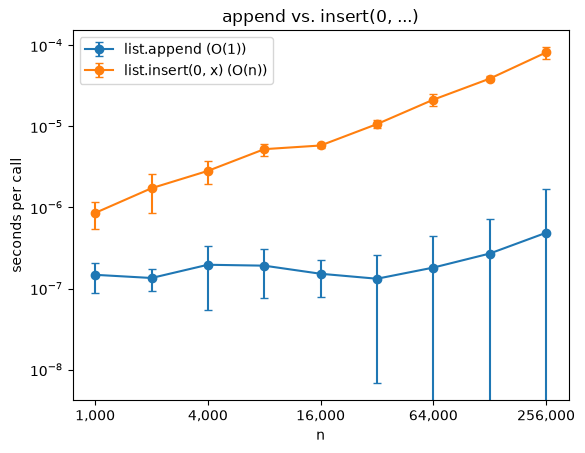

In [31]:
sizes = [1_000, 2_000, 4_000, 8_000, 16_000, 32_000, 64_000, 128_000, 256_000]
append_inputs = [list(range(size)) for size in sizes]
insert_inputs = [list(range(size)) for size in sizes]

append_means, append_stds = time_growth(
    append_inputs, lambda values: values.append(0)
)
insert_means, insert_stds = time_growth(
    insert_inputs, lambda values: values.insert(0, 0)
)

plot_growth(
    sizes,
    {
        "list.append (O(1))": (append_means, append_stds),
        "list.insert(0, x) (O(n))": (insert_means, insert_stds),
    },
    xlabel="n",
    title="append vs. insert(0, ...)",
)

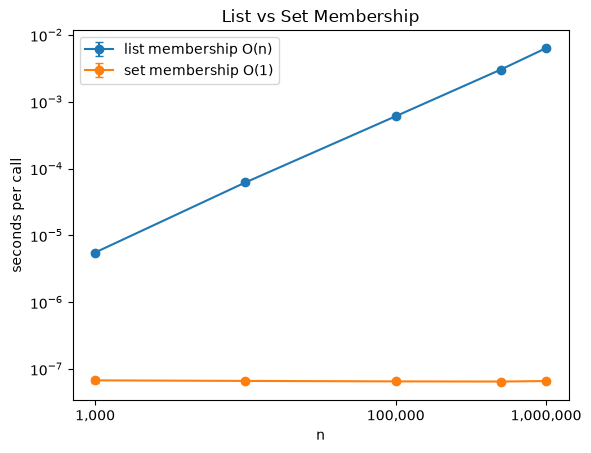

In [38]:
# TODO Membership testing for lists and sets
sizes = [1_000, 10_000, 100_000, 500_000, 1_000_000]

list_inputs = [list(range(size)) for size in sizes]
set_inputs = [set(range(size)) for size in sizes]

list_means, list_stds = time_growth(
    list_inputs,
    lambda values: -1 in values
)

set_means, set_stds = time_growth(
    set_inputs,
    lambda values: -1 in values
)

plot_growth(
    sizes,
    {
        "list membership O(n)": (list_means, list_stds),
        "set membership O(1)": (set_means, set_stds),
    },
    xlabel="n",
    title="List vs Set Membership"
)

**Why this matters:** the `insert(0, ...)` and `list` membership curves climb roughly linearly with `n`, while `append` and `set` membership stay close to flat across orders of magnitude - exactly what $O(n)$ vs. $O(1)$ predicts. Choosing a `set`/`dict` over a `list` for membership testing is one of the cheapest wins available: no algorithm redesign, just the right built-in.

---
## Exercise 2: Profiling execution time and memory

Profiling measures one run of a program. `cProfile` records how many times functions run and how long they take; it helps locate slow parts, but does not explain why an algorithm scales that way. `tracemalloc` tracks Python memory allocations and their peak during a run; it helps compare the temporary memory used by different approaches. Neither tool changes or speeds up the code.

We use the `Pipeline` and `AddGrowthRateStage` classes from Lab 4.

### 2a. Profile each pipeline stage

The next two cells create sample synthetic data and define a three-stage pipeline; run them as provided. In the first exercise cell, profile each stage's `transform` call separately, passing each stage's output to the next stage. Print the stage name and the eight functions with the highest cumulative time for that stage. This lets you compare where the pipeline spends time. Read `ncalls` (number of calls) and `cumtime` (time in a function plus the functions it called). Profiling adds overhead, so use the reports to find hotspots, not as exact benchmarks.

In [39]:
def make_synthetic_worldbank_df(n_countries=50, n_years=40):
    rows = [
        {
            "country": f"country_{country}",
            "year": year,
            "population": None if year == 1980 else 1_000_000 + country * 1000 + year,
        }
        for country in range(n_countries)
        for year in range(1980, 1980 + n_years)
    ]
    return pd.DataFrame(rows)


sample_df = make_synthetic_worldbank_df()

In [40]:
pipeline = Pipeline([
    RenameColumnsStage({"year": "observation_year"}),
    DropMissingStage(["population"]),
    AddGrowthRateStage(
        group_col="country",
        value_col="population",
        date_col="observation_year",
    ),
])

In [81]:
# TODO Use profiler to analyze the performance of the pipeline
# Try to remove steps and see how it affects the performance
data = sample_df.copy()

for stage in pipeline.stages:
    profiler = cProfile.Profile()

    profiler.enable()
    result = stage.transform(data)
    profiler.disable()

    print(f"\nStage: {type(stage).__name__}")

    #.strip_dirs() remove o caminho dos diretorios
    #.sort_stats
    pstats.Stats(profiler) \
        .strip_dirs() \
        .sort_stats("cumulative") \
        .print_stats(8)

    data = result


Stage: RenameColumnsStage
         569 function calls (560 primitive calls) in 0.004 seconds

   Ordered by: cumulative time
   List reduced from 153 to 8 due to restriction <8>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.001    0.001    0.004    0.004 {method '__exit__' of 'sqlite3.Connection' objects}
        1    0.000    0.000    0.003    0.003 pipeline.py:27(transform)
        1    0.000    0.000    0.003    0.003 frame.py:6354(rename)
        1    0.000    0.000    0.003    0.003 generic.py:989(_rename)
        1    0.000    0.000    0.002    0.002 base.py:6252(get_indexer_for)
        1    0.000    0.000    0.002    0.002 base.py:3656(get_indexer)
        2    0.000    0.000    0.001    0.001 base.py:486(__new__)
        1    0.000    0.000    0.001    0.001 base.py:6829(_maybe_cast_listlike_indexer)



Stage: DropMissingStage
         1851 function calls (1797 primitive calls) in 0.007 seconds

   Ordered by: cumulative time
   List 

### 2b. `tracemalloc`: how much Python memory is used?

Compare reading Lab 5's `reviews.txt` into a list with processing it one line at a time. Start tracing immediately before each approach. `get_traced_memory()` returns `(current_bytes, peak_bytes)`; `_` ignores the current value because we want the peak. Stop tracing before measuring the other approach so the results stay separate. `tracemalloc` tracks Python allocations, not all memory used by the whole process.

In [84]:
def read_as_list():
    with open(REVIEWS_PATH) as f:
        return [line.strip() for line in f]


def count_lines_one_at_a_time():
    with open(REVIEWS_PATH) as f:
        return sum(1 for _ in f)

In [87]:
tracemalloc.start()
read_as_list()
_, list_peak_bytes = tracemalloc.get_traced_memory()
tracemalloc.stop()

print(f"list peak:      {list_peak_bytes / 1024:.1f} KiB")


list peak:      253630.7 KiB


In [92]:
# TODO Use the example above to analyze memory usage from count_lines_one_at_a_time()
tracemalloc.start()

count = count_lines_one_at_a_time()

_, stream_peak_bytes = tracemalloc.get_traced_memory()

tracemalloc.stop()

print(f"stream peak: {stream_peak_bytes / 1024:.1f} KiB")
print(f"number of lines: {count}")

stream peak: 35.4 KiB
number of lines: 10000


---
## Exercise 3: Algorithm complexity vs. data complexity

Two implementations of the *same task* can have different Big-O complexity, but even a fixed algorithm's *real* runtime also depends on the *data* it's given - its size, but also its shape (how many duplicates, how sorted it already is, etc.). Big-O captures the first; it says nothing about the second.

Write `count_duplicates_naive(items)` (nested loops, $O(n^2)$) and `count_duplicates_fast(items)` (single pass with a `set`, $O(n)$) using the reviews from `reviews.txt`. First, run both across growing input sizes and plot the timings to confirm the $O(n^2)$ vs. $O(n)$ gap. Then, run `count_duplicates_fast` alone on two same-sized datasets with different *shapes* - the repetitive `reviews.txt` sample vs. an all-unique synthetic list - to see that Big-O alone doesn't predict real runtime.

In [96]:
with open(REVIEWS_PATH) as f:
    all_reviews = [line.strip() for line in f]


def count_duplicates_naive(items: list[str]) -> int:
    """O(n^2): compares every pair of items with nested loops."""
    duplicates = 0

    for i in range(len(items)):
        if items[i] in items[:i]:
            duplicates += 1

    return duplicates

def count_duplicates_fast(items: list[str]) -> int:
    """O(n): a single pass with a set of items already seen."""
    seen = set()
    duplicates = 0

    for item in items:
        if item in seen:
            duplicates += 1
        else:
            seen.add(item)

    return duplicates


# 3a: O(n^2) vs. O(n) as n grows
duplicate_sizes = [200, 400, 800, 1_600, 3_200]
review_inputs = [all_reviews[:size] for size in duplicate_sizes]
naive_means, naive_stds = time_growth(
    review_inputs, count_duplicates_naive, repeats=5
)
fast_means, fast_stds = time_growth(
    review_inputs, count_duplicates_fast, repeats=5
)




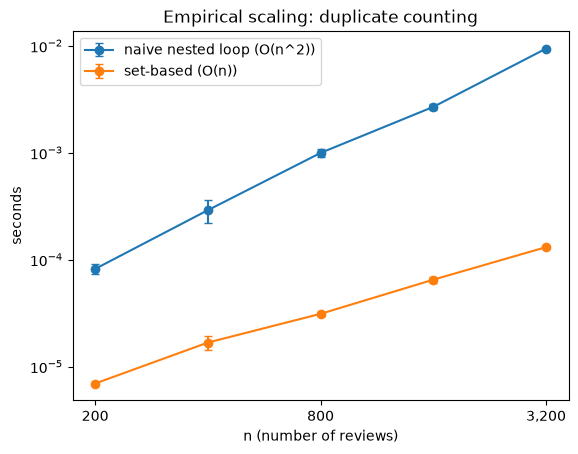

In [99]:
plot_growth(
    duplicate_sizes,
    {
        "naive nested loop (O(n^2))": (naive_means, naive_stds),
        "set-based (O(n))": (fast_means, fast_stds),
    },
    xlabel="n (number of reviews)",
    ylabel="seconds",
    title="Empirical scaling: duplicate counting",
)


In [101]:
# 3b: same O(n) algorithm, different data shape
n = 3_200
repetitive_data = all_reviews[:n]  # only a handful of unique sentences
unique_data = [f"unique review number {i}" for i in range(n)]  # every item distinct
repetitive_time = timeit.timeit(lambda: count_duplicates_fast(repetitive_data), number=5) / 5
unique_time = timeit.timeit(lambda: count_duplicates_fast(unique_data), number=5) / 5

print(f"repetitive data (few unique values): {repetitive_time * 1000:.3f} ms")
print(f"all-unique data (n distinct values): {unique_time * 1000:.3f} ms")

repetitive data (few unique values): 0.309 ms
all-unique data (n distinct values): 0.329 ms


**Algorithm complexity vs. data complexity:** `count_duplicates_fast` is $O(n)$ regardless of input - the Big-O classification only depends on the *algorithm's shape*, not on what's inside the list. But the last comparison shows the *actual* runtime still shifts with the *data's* shape: hashing ~3,200 distinct long strings behaves differently from repeatedly hitting the same handful of hash buckets for a mostly-repetitive dataset. Some effects only show up empirically, on real or realistic data, not from Big-O alone.

---
## Coming next: parallelism

Everything so far has been about running *one* thing at a time, faster or with less memory. The natural next question - can we run several things *at once*? - needs the GIL, threads vs. processes, and `asyncio`, which are the subject of **Lab 7: Parallel Programming with Python**. Lab 7 picks up directly from the profiling results and CPU-/IO-bound distinctions established here.

---
## Wrap-up questions (choose one answer for each)

1. Why does `list.insert(0, x)` scale linearly while `list.append(x)` is amortized constant time?
   - A. Both operations copy the whole list.
   - B. Inserting at the front shifts existing items; appending usually adds one item at the end.
   - C. `append` searches for `x` before adding it.
   - D. The difference is only caused by the values stored in the list.
2. What does the `cProfile` report in Exercise 2a show?
   - A. The exact Big-O complexity of every function.
   - B. Peak memory used by the pipeline.
   - C. Function call counts and time spent in functions, including cumulative time.
   - D. A faster version of the pipeline.
3. Two inputs have the same length and are processed by the same $O(n)$ algorithm. Why might their measured runtimes still differ?
   - A. Big-O guarantees identical runtimes for equal-sized inputs.
   - B. Data values and distribution can affect per-item work and runtime constants.
   - C. One input must have a different Big-O complexity.
   - D. Runtime can only differ if the computer has changed.


> #### 📚 Further reading
> - Python docs, [`timeit`](https://docs.python.org/3/library/timeit.html) and [`cProfile`/`pstats`](https://docs.python.org/3/library/profile.html) - the tools used in Exercises 1 and 2, including direct `cProfile` use in the pipeline example.
> - Python docs, [`tracemalloc`](https://docs.python.org/3/library/tracemalloc.html) - the memory-profiling tool used in Exercise 2b to make Lab 5's "generators save memory" claim measurable.
> - [Big-O Cheat Sheet](https://www.bigocheatsheet.com/) - complexity of common data structures/algorithms, useful as a quick reference alongside Exercise 1's empirical measurements.
> - Ramalho, *Fluent Python* (2nd ed.), concurrency chapters - the GIL and threads/processes/`asyncio`, picked up next in Lab 7.